# Notebook 10 — OpenCV Features & Feature Matching

## 1. What problem are we solving?

**Intuition:** Imagine taking a photo of a cat, then taking another photo where the same image is rotated or resized. We want to recognize which parts correspond.

**Straight definition:** Feature matching finds corresponding visual features between two images.

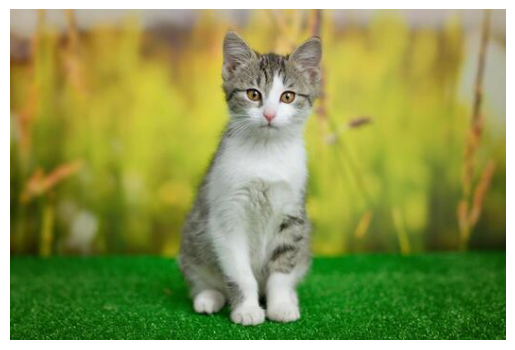

In [62]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread("cat.jpg")
if img is None:
    raise FileNotFoundError("cat.jpg not found")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)
plt.axis("off")
plt.show()

## 2. What is a feature?

**Intuition:** A feature is a visually interesting landmark — for example, a corner, eye, or distinctive texture.

**Straight definition:** A feature is local image information that can be detected and described reliably.

We will represent important features using **keypoints**.

## 3. Keypoint

**Intuition:** Think of a keypoint as putting a pin on an interesting location in the image.

**Straight definition:** A keypoint stores the location and properties of a detected image feature.

**Example:** ORB can automatically find these pins.

Number of keypoints: 485


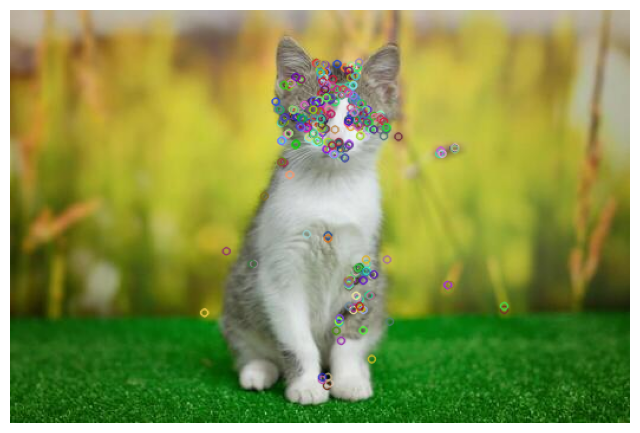

In [63]:
orb = cv2.ORB_create()
keypoints = orb.detect(img, None)

print("Number of keypoints:", len(keypoints))

view = cv2.drawKeypoints(img_rgb, keypoints, None)
plt.figure(figsize=(8, 6))
plt.imshow(view)
plt.axis("off")
plt.show()

## 4. Descriptor

**Intuition:** A keypoint tells us **where** the landmark is. A descriptor is like its **fingerprint** — it tells us what the surrounding region looks like.

**Straight definition:** A descriptor is a numerical representation of the image region around a keypoint.

**Example:**

Keypoints: 485
Descriptor shape: (485, 32)


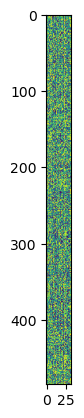

In [64]:
keypoints, descriptors = orb.detectAndCompute(img, None)

print("Keypoints:", len(keypoints))
print("Descriptor shape:", descriptors.shape)
plt.imshow(descriptors)

## 5. The basic pipeline

```text
Image
  ↓
Find keypoints
  ↓
Create descriptors
  ↓
Compare descriptors from two images
  ↓
Find matching features
```

This is the main idea of the entire notebook.

## 6. ORB

**Intuition:** ORB is a fast tool that finds interesting points and creates compact fingerprints for them.

**Straight definition:** ORB combines FAST-style keypoint detection with a binary BRIEF-style descriptor and orientation handling.

**Example:**

In [65]:
orb = cv2.ORB_create(nfeatures=500)
keypoints, descriptors = orb.detectAndCompute(img, None)

print("Keypoints:", len(keypoints))
print("Descriptor shape:", descriptors.shape)

Keypoints: 485
Descriptor shape: (485, 32)


## 7. FAST

**Intuition:** FAST mainly asks: **“Does this location look like a corner?”**

**Straight definition:** FAST is a corner/keypoint detector based on intensity comparisons around a candidate pixel.

**Example:**

In [66]:
fast = cv2.FastFeatureDetector_create()
fast_keypoints = fast.detect(img, None)
print("FAST keypoints:", len(fast_keypoints))

FAST keypoints: 1901


## 8. Why do we need two images?

Matching needs something to compare. We will create a second view from `cat.jpg` by rotating and resizing it.

```text
cat.jpg → image 1
cat.jpg → rotate + resize → image 2
```

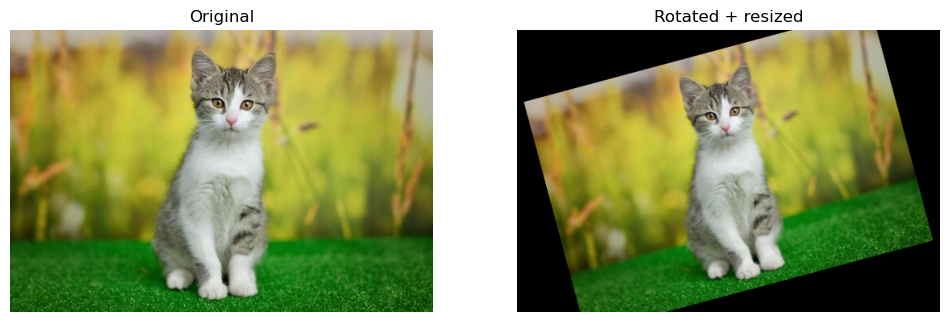

In [67]:
h, w = img.shape[:2]
M = cv2.getRotationMatrix2D((w/2, h/2), 15, 0.85)
img2 = cv2.warpAffine(img, M, (w, h))

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.imshow(img_rgb)
plt.axis("off")
plt.title("Original")
plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Rotated + resized")
plt.show()

## 9. Matching

**Intuition:** We have fingerprints from image 1 and image 2. We ask: **which fingerprints look most alike?**

**Straight definition:** Feature matching pairs descriptors from two images according to descriptor distance.

For ORB, we normally use **Hamming distance**.

## 10. Hamming distance

**Intuition:** Count how many binary positions are different.

```text
A = 101100
B = 100110
      ↑  ↑

Distance = 2
```

**Straight definition:** Hamming distance counts differing bits. It is appropriate for ORB’s binary descriptors.

## 11. Brute-Force Matcher

**Intuition:** For every feature in image 1, compare it with features in image 2 and find the closest one.

**Straight definition:** `BFMatcher` performs descriptor-to-descriptor comparison using a selected distance metric.

**Example:**

In [68]:
orb = cv2.ORB_create(nfeatures=800)
kp1, des1 = orb.detectAndCompute(img, None)
kp2, des2 = orb.detectAndCompute(img2, None)

bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
matches = bf.match(des1, des2)
matches = sorted(matches, key=lambda m: m.distance)

print("Matches:", len(matches))
print("Best distance:", matches[0].distance)

Matches: 407
Best distance: 7.0


## 12. Visualizing matches

**Intuition:** Draw a line between two corresponding keypoints. If many lines connect similar places, the matching is working.

**Straight definition:** `drawMatches()` visualizes descriptor correspondences between two images.

**Example:**

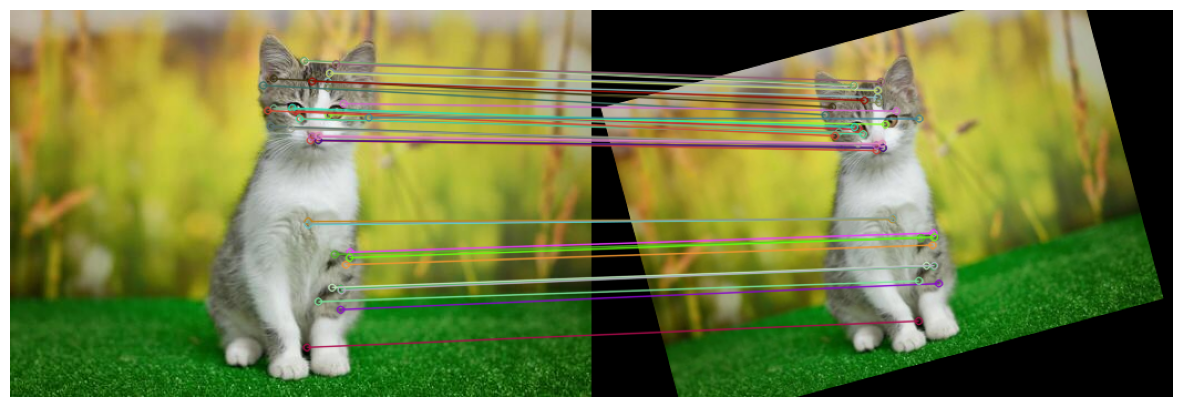

In [69]:
result = cv2.drawMatches(
    img, kp1, img2, kp2, matches[:40], None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(15,7))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

## 13. Why are some matches wrong?

**Intuition:** Two unrelated regions can sometimes look similar. The closest match is not automatically correct.

**Straight definition:** Descriptor similarity alone can produce ambiguous or incorrect correspondences.

So we need a way to reject weak matches.

## 14. KNN matching

**Intuition:** Instead of keeping only the best candidate, keep the **two best candidates**. Then we can see whether the best one is clearly better.

**Straight definition:** `knnMatch(..., k=2)` returns the two nearest descriptor matches for each descriptor.

**Example:**

In [70]:
bf = cv2.BFMatcher(cv2.NORM_HAMMING)
knn_matches = bf.knnMatch(des1, des2, k=2)
print("Descriptor groups:", len(knn_matches))

Descriptor groups: 727


## 15. Ratio test

**Intuition:**

```text
Best = 20, Second = 80  → clearly better → good
Best = 20, Second = 22  → almost tied     → uncertain
```

**Straight definition:** Accept a match when

\[d_1 < r d_2\]

A common ratio is `0.75`.

In [71]:
good_matches = []

for m, n in knn_matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

print("Good matches:", len(good_matches))

Good matches: 407


## 16. SIFT

**Intuition:** SIFT looks for stronger landmarks that can remain recognizable when an image changes scale or rotation.

**Straight definition:** SIFT detects scale-space features and creates floating-point descriptors designed to be robust to scale and rotation.

**Important:** SIFT descriptors use **L2 distance**, unlike ORB’s Hamming distance.

In [72]:
sift = cv2.SIFT_create()
kp1_s, des1_s = sift.detectAndCompute(img, None)
kp2_s, des2_s = sift.detectAndCompute(img2, None)

print("SIFT keypoints in image 1:", len(kp1_s))
print("Descriptor shape:", des1_s.shape)

SIFT keypoints in image 1: 425
Descriptor shape: (425, 128)


## 17. ORB vs SIFT

| ORB | SIFT |
|---|---|
| Binary descriptor | Floating-point descriptor |
| Hamming distance | L2 distance |
| Usually faster | Usually more computationally expensive |

For now, remember only this:

**ORB → binary → Hamming**

**SIFT → floating point → L2**

## 18. SIFT matching example

**Intuition:** Same matching idea as ORB; only the descriptor type and distance change.

**Straight definition:** Use a brute-force matcher with `NORM_L2` for SIFT descriptors.

In [73]:
bf_sift = cv2.BFMatcher(cv2.NORM_L2)
knn_sift = bf_sift.knnMatch(des1_s, des2_s, k=2)

good_sift = []
for m, n in knn_sift:
    if m.distance < 0.75 * n.distance:
        good_sift.append(m)

print("Good SIFT matches:", len(good_sift))

Good SIFT matches: 206


## 19. Homography

**Intuition:** Matching says **which point corresponds to which point**. Homography uses those correspondences to estimate **how one image view maps to another**.

**Straight definition:** A homography is a 3×3 projective transformation matrix between two planar views.

\[
\begin{bmatrix}x'\\y'\\w\end{bmatrix}=H\begin{bmatrix}x\\y\\1\end{bmatrix}
\]

Then divide by `w` to get the final coordinates.

## 20. RANSAC

**Intuition:** Some matches are wrong. RANSAC tries to find a transformation supported by the largest consistent group and ignores outliers.

**Straight definition:** RANSAC estimates a model while rejecting data points that do not agree with that model.

In OpenCV, `findHomography(..., cv2.RANSAC, ...)` can do this for us.

In [74]:
if len(good_matches) >= 4:
    src = np.float32([kp1[m.queryIdx].pt for m in good_matches]).reshape(-1,1,2)
    dst = np.float32([kp2[m.trainIdx].pt for m in good_matches]).reshape(-1,1,2)

    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)

    if H is not None:
        print("Homography:\n", H)
        print("Inliers:", int(mask.sum()))
        print("Outliers:", len(mask) - int(mask.sum()))
    else:
        print("Homography could not be estimated.")
else:
    print("Need at least 4 good matches.")

Homography:
 [[ 7.93072471e-01  2.18441812e-01  1.26935050e+01]
 [-2.22614355e-01  8.10373967e-01  8.93411721e+01]
 [-5.30521689e-05  3.62327307e-06  1.00000000e+00]]
Inliers: 406
Outliers: 1


## 21. The whole idea in one picture

```text
cat.jpg
   ↓
Find keypoints
   ↓
Create descriptors
   ↓
Do the same for second image
   ↓
Compare descriptors
   ↓
Good matches
   ↓
(Optional) Homography + RANSAC
```

### Remember
- **Keypoint** → where is the interesting point?
- **Descriptor** → what does it look like?
- **Match** → which two features correspond?
- **Hamming** → distance for binary ORB descriptors
- **L2** → distance commonly used for SIFT descriptors
- **Homography** → geometric mapping
- **RANSAC** → rejects inconsistent matches